# Chapter 3. Don't peek at the exam paper

*Train, validation, test; the seed; the baseline.*

A student who sees the board exam paper in advance scores well and has learned nothing anyone can trust. A model is the same. This chapter splits twenty invented Kalpa members into three slices, shows what the seed does, and scores the baseline every model has to beat.

By the end you can say what each slice is for and which one is spent once, why the seed is written down, and what the dumbest model scores on a table where most members do not come back.

**Search terms:** train validation test split, holdout set, random seed reproducibility, baseline model, majority class.

In [1]:
# Tools for this notebook, and one helper that prints a check as PASS or FAIL.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def check(label, ok):
    print(("PASS  " if ok else "FAIL  ") + label)

In [2]:
# Twenty Kalpa members, invented for teaching: 5 came back within 90 days, 15 did not.
members = pd.DataFrame({"member": [f"M{i:02d}" for i in range(1, 21)],
                        "repeat_90d": [1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0]})
print(members.T.to_string(header=False))
print(f"share who came back: {members['repeat_90d'].mean():.2f}")

member      M01  M02  M03  M04  M05  M06  M07  M08  M09  M10  M11  M12  M13  M14  M15  M16  M17  M18  M19  M20
repeat_90d    1    0    0    1    0    0    0    1    0    0    0    0    1    0    0    0    1    0    0    0
share who came back: 0.25


## Three slices, three jobs

| Slice | The school version | The model version |
|---|---|---|
| train | the practice papers you study from | the rows the model learns from |
| validation | the mock exams you take as often as you like | the rows you compare models and settings on |
| test | the board exam, sat once | the rows you score the chosen model on, once, at the end |

**Predict before you run.** Split with seed 42 and again with seed 7. Will the test slice hold the same members? (a) yes, always (b) no, the seed decides which rows land where

In [3]:
# Split 12 / 4 / 4, stratified so every slice keeps the share who came back, with two different seeds.
from sklearn.model_selection import train_test_split

def three_way(df, seed):
    rest, test = train_test_split(df, test_size=4, stratify=df["repeat_90d"], random_state=seed)
    train, val = train_test_split(rest, test_size=4, stratify=rest["repeat_90d"], random_state=seed)
    return train, val, test

slices = {}
for seed in (42, 7):
    tr, va, te = three_way(members, seed)
    slices[seed] = (tr, va, te)
    print(f"seed {seed:2d}  test: {sorted(te['member'])}   validation: {sorted(va['member'])}")
check("the seed changes which members are in the test slice", set(slices[42][2]["member"]) != set(slices[7][2]["member"]))
check("seed 42 gives the same test slice when run again", set(three_way(members, 42)[2]["member"]) == set(slices[42][2]["member"]))

seed 42  test: ['M06', 'M08', 'M10', 'M18']   validation: ['M07', 'M09', 'M13', 'M14']
seed  7  test: ['M01', 'M07', 'M10', 'M14']   validation: ['M02', 'M06', 'M13', 'M18']
PASS  the seed changes which members are in the test slice
PASS  seed 42 gives the same test slice when run again


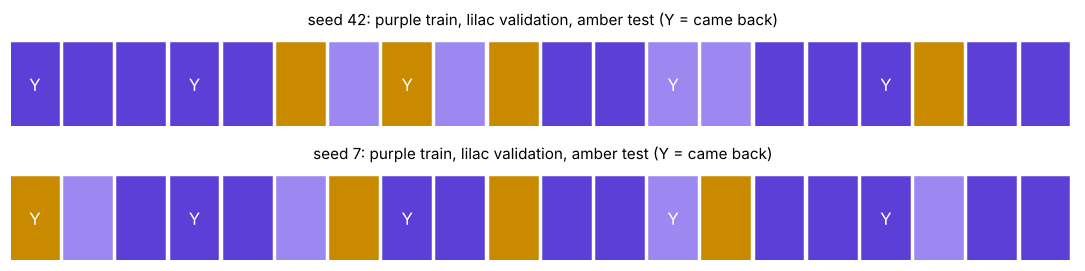

In [4]:
# Picture both splits: one square per member, coloured by slice.
fig, axes = plt.subplots(2, 1, figsize=(10, 2.6))
colour = {"train": "#5B3FD6", "validation": "#9C88F0", "test": "#C98A00"}
for ax, seed in zip(axes, (42, 7)):
    tr, va, te = slices[seed]
    where = {m: "train" for m in tr["member"]} | {m: "validation" for m in va["member"]} | {m: "test" for m in te["member"]}
    for i, m in enumerate(members["member"]):
        ax.add_patch(plt.Rectangle((i, 0), 0.9, 0.9, color=colour[where[m]]))
        ax.text(i + 0.45, 0.45, "Y" if members.loc[i, "repeat_90d"] else "", ha="center", va="center", color="white")
    ax.set_xlim(0, 20); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title(f"seed {seed}: purple train, lilac validation, amber test (Y = came back)", fontsize=10)
plt.tight_layout(); plt.show()

**What happened.** The answer is (b). The seed is the shuffle; a different seed is a different exam paper. Writing `random_state=42` into the notebook is what lets a teammate get the same slices, the same baseline and the same score.

## What does the dumbest model score?

The baseline for a will-they question is the majority class: say "no" for everyone. For a how-much question it is the mean: predict the average spend for everyone. A model is worth building only if it beats this.

**Predict before you run.** Saying "no" to all 20 members is right how often? (a) 25 percent (b) 50 percent (c) 75 percent (d) 95 percent

In [5]:
# The majority-class baseline, by hand and by code.
from sklearn.dummy import DummyClassifier
by_hand = (members["repeat_90d"] == 0).mean()
dummy = DummyClassifier(strategy="most_frequent").fit(members[["member"]], members["repeat_90d"])
by_code = (dummy.predict(members[["member"]]) == members["repeat_90d"]).mean()
print(f"say no to everyone: right {int(by_hand * 20)} of 20, accuracy {by_hand:.2f} (by hand) and {by_code:.2f} (by code)")
check("the hand count and the DummyClassifier agree", by_hand == by_code)

say no to everyone: right 15 of 20, accuracy 0.75 (by hand) and 0.75 (by code)
PASS  the hand count and the DummyClassifier agree


**What happened.** The answer is (c): 15 of 20, 75 percent, by knowing nothing about any member. A model that scores 75 percent here has learned only the share who came back.

**The flip.** The majority baseline is the right bar while classes are uneven. When a cheap rule exists (for example "nudge members who bought twice last quarter"), that rule is the stronger baseline, and the model has to beat it instead.

## What did this chapter establish?

| Question | Answer |
|---|---|
| What is each slice for? | train learns, validation compares, test is scored once at the end |
| Which slice is spent once? | test: any choice made by its score turns it into a second validation slice |
| What does the seed do? | fixes the shuffle, so everyone gets the same slices and the same baseline |
| What is the baseline? | the majority class for will-they, the mean for how-much; here 75 percent |

**Interview line:** "Train is where the model learns, validation is where I choose, and test is spent once on the model I chose; I state the seed, and I report the model next to its baseline, because a score means nothing without the bar it cleared."